# 3.5_brain_coverage_tsnr 脑覆盖率与 tSNR — sub-01 ses-test

tSNR=时间均值/时间标准差，脑覆盖率需配准后预期脑掩模。

保存未去均值 BOLD 的 tSNR；预期脑/ROI mask 与可观察 FOV 同空间后计算覆盖，分区审查 dropout。

真实输入、处理前后、可复用关键代码、可视化与量化均在下面。两次采集仅教学few-shot，不能确定最优方法。

**限制：** 真实 tSNR 已测；预期解剖脑mask未取得，脑覆盖率=NOT_MEASURED。

In [1]:
from pathlib import Path
import sys, os, importlib.util, json, inspect
ROOT = Path(os.environ["FMRI_REFERENCE_ROOT"]).resolve() if "FMRI_REFERENCE_ROOT" in os.environ else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"fmri_reference"/"core.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from repository or set FMRI_REFERENCE_ROOT")
sys.path.insert(0, str(ROOT))
from fmri_reference.core import load_sample
spec = importlib.util.spec_from_file_location("category_reference", ROOT / "03_artifacts_quality_control/3.5_brain_coverage_tsnr/src/reference.py")
reference = importlib.util.module_from_spec(spec); spec.loader.exec_module(reference)
SESSION = "test"
sample = load_sample(ROOT, SESSION)
print("REAL INPUT:", sample["path"])
print(json.dumps(sample["geometry"], indent=2))
print({k:v for k,v in sample["timing"].items() if k != "onsets_seconds"})
print("before mean/std:", sample["signals"].mean(), sample["signals"].std(ddof=1))


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


REAL INPUT: /Users/liuxiang/fMRI-preprocess/standard-reference/data/ds000114/sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz
{
  "shape": [
    64,
    64,
    30,
    184
  ],
  "orientation": [
    "L",
    "A",
    "S"
  ],
  "spacing_mm": [
    3.999999951454272,
    4.000000086623366,
    3.9999749144565446
  ],
  "qform_code": 1,
  "sform_code": 1,
  "qform_sform_disagree": false,
  "affine_ras_mm": [
    [
      -3.9947142601013184,
      -0.20423313975334167,
      0.022935329005122185,
      130.64169311523438
    ],
    [
      -0.205448716878891,
      3.982606887817383,
      -0.3108908534049988,
      -97.47322845458984
    ],
    [
      0.006958197336643934,
      0.31165990233421326,
      3.9878089427948,
      -80.64657592773438
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ]
}
{'tr_seconds': 2.5, 'sampling_hz': 0.4, 'nyquist_hz': 0.2, 'n_volumes': 184, 'sample_span_seconds': 457.5, 'nominal_duration_seconds': 460.0}
before mean/

## 关键函数与执行

所有源码可追踪。配准/生理/组织输入不存在时，不生成虚构校正结果。

In [2]:
print(inspect.getsource(reference.apply))

def coverage(observed,expected):
    o=np.asarray(observed);e=np.asarray(expected)
    if o.shape!=e.shape or o.dtype!=bool or e.dtype!=bool or not e.any():raise ValueError('Nonempty expected boolean mask in same verified world grid required')
    return float((o&e).sum()/e.sum())



{
  "input": "data/ds000114/sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz",
  "session": "test",
  "kind": "coverage",
  "tr_seconds": 2.5,
  "n_input": 184,
  "feature_scope": "128 deterministic voxels from estimated EPI mask, not full brain",
  "before": {
    "shape": [
      184,
      128
    ],
    "mean_abs": 1195.394276494565,
    "median_sample_std": 48.296438755295526,
    "q01": 266.0,
    "q99": 1743.4700000000048
  },
  "production_pipeline": "NOT_RUN",
  "scientific_best_method": "INSUFFICIENT_EVIDENCE",
  "raw_tsnr_median": 28.00429321936711,
  "raw_tsnr_q10": 5.957362219586277,
  "brain_coverage": "NOT_MEASURED",
  "mask_scope": "Estimated EPI mask does not provide expected anatomical brain coverage",
  "after": {
    "shape": [
      184,
      128
    ],
    "mean_abs": 1195.394276494565,
    "median_sample_std": 48.296438755295526,
    "q01": 266.0,
    "q99": 1743.4700000000048
  },
  "evidence_status": "REAL_DATA_PRIMITIVE_EXECUTED",
  "limit

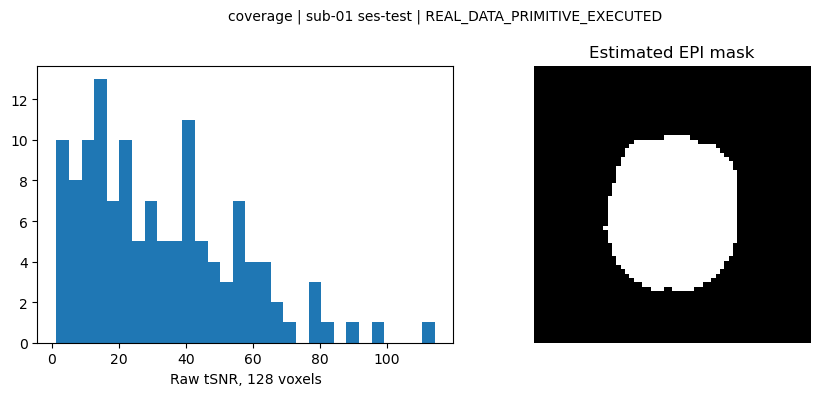

In [3]:
metrics, fig = reference.demonstrate(ROOT, SESSION, variant=0, outdir=ROOT/"03_artifacts_quality_control/3.5_brain_coverage_tsnr/results/test")
print(json.dumps(metrics, indent=2))
from IPython.display import display
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

## 常见错误与阻止机制

以下故意提供不满足科学前提的输入。报错是负对照，不是处理失败被掩盖。

In [4]:
try:
    reference.error_example("coverage")
except (ValueError, FileNotFoundError) as e:
    print("EXPECTED REJECTION:", type(e).__name__, str(e))
else:
    raise AssertionError("Invalid scientific input was accepted")

EXPECTED REJECTION: FileNotFoundError Required scientific inputs absent: /missing_scientific_inputs/coverage


## 解释与后续验证

数值不变性/投影正交性只验证实现数学性质。更低DVARS、更高tSNR、更低配准目标值不是神经信号保真证明。正式推荐需同数据、固定参数、跨受试者的独立下游证据。详见本小类README、references和根目录验证报告。